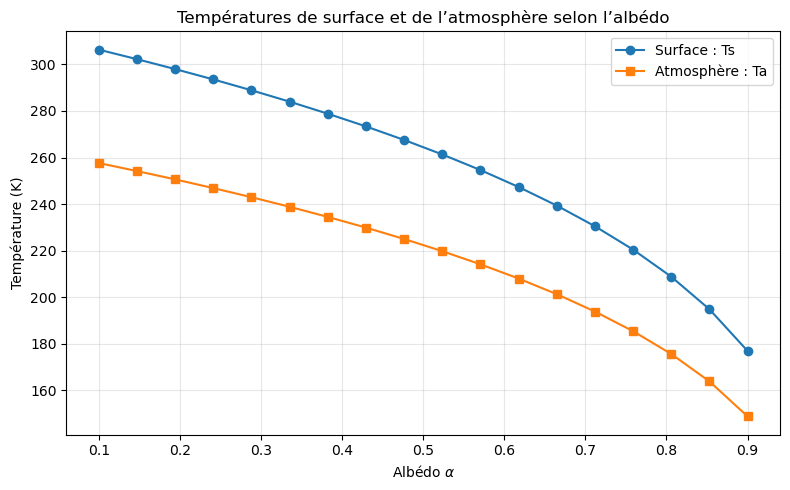

In [1]:
import numpy as np
import matplotlib.pyplot as plt

epsilon_s=1
epsilon_a=0.77
S0=1365
sigma = 5.67e-8
alpha = np.linspace(0.1, 0.9, 18)

Ts = ((1 - alpha) * S0 /(4 * sigma * epsilon_s * (1 - epsilon_a / 2)))**(1/4)
Ta = (epsilon_s * Ts**4 / 2)**(1/4)

plt.figure(figsize=(8, 5))

plt.plot(alpha, Ts, marker="o", label="Surface : Ts")
plt.plot(alpha, Ta, marker="s", label="Atmosphère : Ta")

plt.xlabel(r"Albédo $\alpha$")
plt.ylabel("Température (K)")
plt.title("Températures de surface et de l’atmosphère selon l’albédo")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("comparaison_T_albedo.png", bbox_inches="tight")
plt.show()

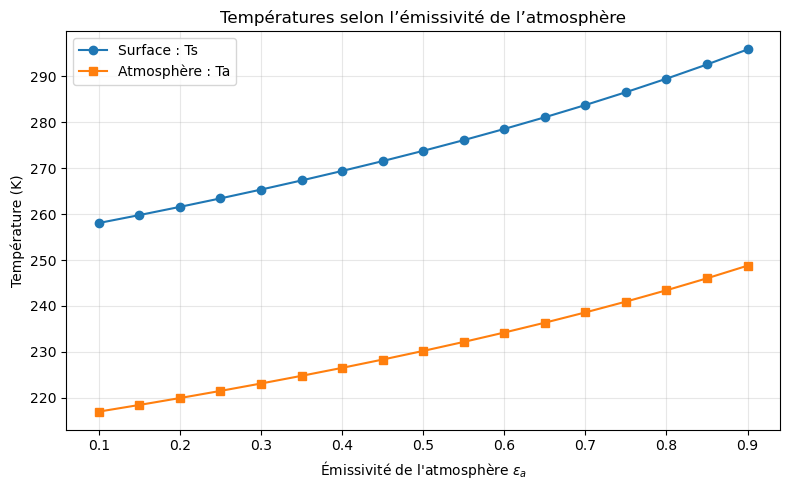

In [2]:
import numpy as np
import matplotlib.pyplot as plt

epsilon_s = 1
epsilon_a = np.linspace(0.1, 0.9, 17)
alpha = 0.3
S0 = 1365
sigma = 5.67e-8

Ts = ((1 - alpha) * S0 /
      (4 * sigma * epsilon_s * (1 - epsilon_a / 2)))**(1/4)

Ta = (epsilon_s * Ts**4 / 2)**(1/4)

plt.figure(figsize=(8, 5))

plt.plot(epsilon_a, Ts, marker="o", label="Surface : Ts")
plt.plot(epsilon_a, Ta, marker="s", label="Atmosphère : Ta")

plt.xlabel(r"Émissivité de l'atmosphère $\varepsilon_a$")
plt.ylabel("Température (K)")
plt.title("Températures selon l’émissivité de l’atmosphère")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("comparaison_T_emissivite.png", bbox_inches="tight")
plt.show()


 
 ********************************************
Control simulation 
********************************************
AttrDict({'Ts': Field([288.]), 'Tatm': Field([288., 288., 288., 288., 288., 288., 288., 288., 288., 288., 288.,
       288., 288., 288., 288., 288., 288., 288., 288., 288., 288., 288.,
       288., 288., 288., 288., 288., 288., 288., 288.])})


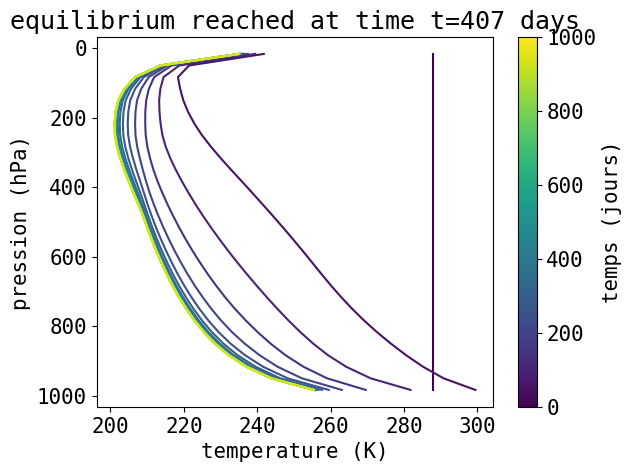

output figure:  control_temp.png


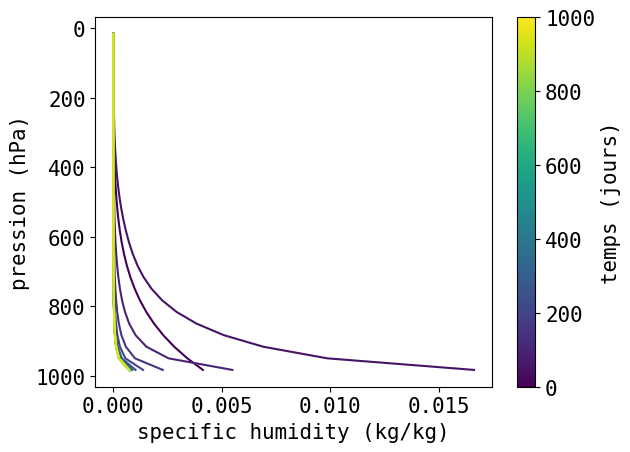

output figure:  control_temp.png
diagnostics:  {'OLR': Field([243.1363796]), 'OLRclr': Field([243.1363796]), 'OLRcld': Field([0.]), 'TdotLW': Field([-3.56209571, -0.75844777, -0.35741892, -0.26819342, -0.21639742,
       -0.18621983, -0.16427303, -0.14924665, -0.13994072, -0.13455319,
       -0.13125081, -0.1286825 , -0.12691451, -0.12510342, -0.12430928,
       -0.13075466, -0.13793417, -0.1457421 , -0.15508095, -0.16576379,
       -0.1775802 , -0.19241839, -0.21198472, -0.23771766, -0.27268611,
       -0.32247573, -0.39864447, -0.52564361, -0.76037454, -1.38073196]), 'TdotLW_clr': Field([-3.56209571, -0.75844777, -0.35741892, -0.26819342, -0.21639742,
       -0.18621983, -0.16427303, -0.14924665, -0.13994072, -0.13455319,
       -0.13125081, -0.1286825 , -0.12691451, -0.12510342, -0.12430928,
       -0.13075466, -0.13793417, -0.1457421 , -0.15508095, -0.16576379,
       -0.1775802 , -0.19241839, -0.21198472, -0.23771766, -0.27268611,
       -0.32247573, -0.39864447, -0.52564361, -0.7

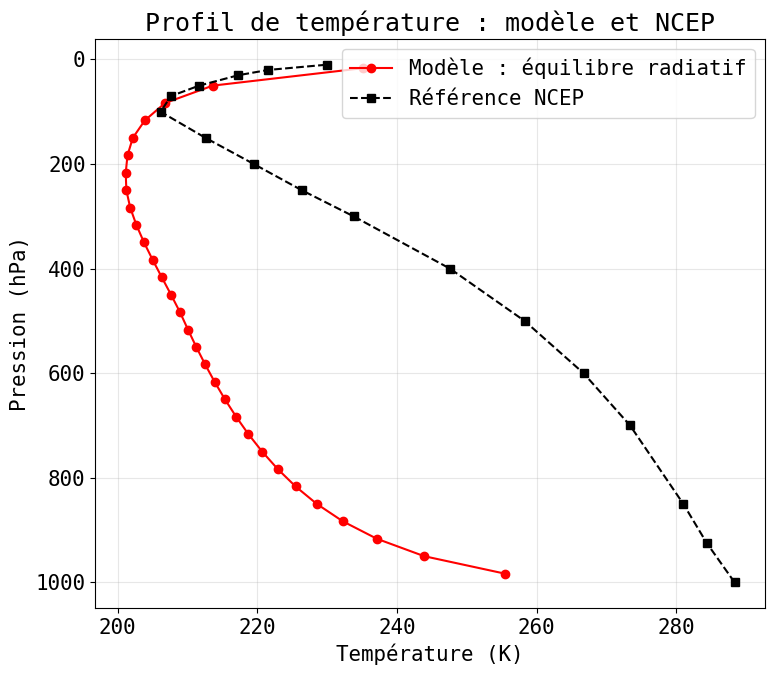


--- Flux au sommet de l'atmosphère (W/m²) ---
Solaire incident : 341.30
Solaire réfléchi : 98.17
Solaire absorbé par le système : 243.13
Infrarouge sortant : 243.14
Bilan net entrant : -0.00314

--- Flux à la surface (W/m²) ---
Solaire descendant : 262.06
Solaire réfléchi : 65.51
Solaire absorbé : 196.54
Infrarouge descendant : 145.85
Infrarouge montant : 342.39
Perte infrarouge nette : 196.54
Bilan net entrant : -0.00032


In [7]:
#!/usr/bin/env python
# coding: utf-8
import os
import numpy as np
import matplotlib.pyplot as plt
import climlab
from climlab import constants as constants
import sys
import xarray as xr
import pdb
import copy as cp

# Pour fixer la taille de la police partout
import matplotlib as matplotlib
font = {'family' : 'monospace',
        'size'   : 15}
matplotlib.rc('font', **font)

#outpath='./figures/' # repertoire pour les figures
#os.makedirs(outpath, exist_ok=True) # cree le repertoire s'il n'existe pas

# Parametres
alb=.25 # Albedo surface
Nz=30 # nombre de niveaux verticaux

# Chargement du profil vertical de température de référence de la réanalyse NCEP
ncep_lev=np.load('D:/UQAM/session_5/labo_3/experience_3/Experience3_fichiers/npy/ncep_lev.npy')
ncep_T=np.load('D:/UQAM/session_5/labo_3/experience_3/Experience3_fichiers/npy/ncep_T.npy') + 273.15

#  Variables d'état (température de l'air et de la surface)
state = climlab.column_state(num_lev=30)

#  Humidité relative fixe
h2o = climlab.radiation.ManabeWaterVapor(name='WaterVapor', state=state)

#  Couplage de la vapeur d'eau au rayonnement
rad = climlab.radiation.RRTMG(name='Radiation', state=state, specific_humidity=h2o.q, albedo=alb)

# Creation d'un modele couplé avec rayonemment et vapour d'eau
rcm = climlab.couple([rad,h2o], name='Radiative-Equilibrium Model')
rcm2 = climlab.process_like(rcm) # creation d'un clone du modele rcm

print('\n','\n','********************************************')
print('Control simulation ')
print('********************************************')

# Rendre l'état initial isotherme
rcm.state.Tatm[:] = rcm.state.Ts
T=[]
q=[]
t_eq=None # premier pas de temps (en jours) ou l'equilibre est atteint
n_ok=0    # nombre de pas consecutifs avec |ASR-OLR| < 1 W/m2
n_req=30  # on exige 30 jours consecutifs pour eviter un croisement transitoire
nt=1000  # nombre de pas de temps (jours)
# Palette sequentielle : la couleur passe progressivement du debut (fonce) a la fin (clair) de la simulation
cmap=plt.cm.viridis
norm=matplotlib.colors.Normalize(vmin=0, vmax=nt)
print(state)

# Graphique de la température (un profil tous les 50 pas de temps pour garder la figure lisible)
for t in range(nt):
    T.append(cp.deepcopy(rcm.Tatm))
    q.append(cp.deepcopy(rcm.q))
    if t%50==0:
        plt.plot(rcm.Tatm,rcm.lev,color=cmap(norm(t)))
    rcm.step_forward() # avance le modèle d'un pas de temps (1 jour)
    if abs(rcm.ASR - rcm.OLR)<1: # en W/m2
        n_ok+=1
        if n_ok==n_req and t_eq is None:
            t_eq=t-n_req+1
    else:
        n_ok=0
if t_eq is None:
    plt.title('equilibrium not reached after '+str(nt)+' days')
else:
    plt.title('equilibrium reached at time t='+str(t_eq)+' days')
plt.xlabel('temperature (K)')
plt.ylabel('pression (hPa)')
plt.gca().invert_yaxis()
plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=plt.gca(), label='temps (jours)')
fig_name='control_temp.png'
plt.savefig(fig_name,bbox_inches='tight')
plt.show()
plt.close()
print('output figure: ', fig_name)

# Graphique de l'humidité
for t in range(0,nt,50):
    plt.plot(q[t],rcm.lev,color=cmap(norm(t)))
plt.xlabel('specific humidity (kg/kg)')
plt.ylabel('pression (hPa)')

plt.gca().invert_yaxis()
plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=plt.gca(), label='temps (jours)')
plt.savefig("humidité_controle",bbox_inches='tight')
plt.show()
plt.close()
print('output figure: ', fig_name)

# Quel est la sortie du modèle ?
print('diagnostics: ',rcm.diagnostics,'\n')
print('tendencies',rcm.tendencies,'\n')
print('Tair: ',rcm.Tatm,'\n')
# Les flux sont definis aux interfaces : indice 0 = sommet de l'atmosphere, indice -1 = surface
print('albedo de surface',rcm.SW_flux_up[-1]/rcm.SW_flux_down[-1],'\n')
print('albedo planetaire',rcm.SW_flux_up[0]/rcm.SW_flux_down[0],'\n')
print('co2',rad.absorber_vmr['CO2'],'\n') # rapport de mélange volumique
print('ch4',rad.absorber_vmr['CH4'],'\n') # rapport de mélange volumique


# Température finale de surface
Ts_final = np.asarray(rcm.Ts).item()

print(f"Température finale de surface : {Ts_final:.2f} K")
print(f"Température finale de surface : {Ts_final - 273.15:.2f} °C")

# Comparaison du profil final avec NCEP
fig, ax = plt.subplots(figsize=(8, 7))

ax.plot(rcm.Tatm,rcm.lev,color="red",marker="o",label="Modèle : équilibre radiatif")
ax.plot(ncep_T,ncep_lev,color="black",linestyle="--",marker="s",label="Référence NCEP")

ax.set_xlabel("Température (K)")
ax.set_ylabel("Pression (hPa)")
ax.set_title("Profil de température : modèle et NCEP")
ax.invert_yaxis()
ax.legend()
ax.grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig("comparaison_NCEP.png", bbox_inches="tight")
plt.show()

# flux nécessaire plus loin
def valeur(x):
    return np.asarray(x).item()

print("\n--- Flux au sommet de l'atmosphère (W/m²) ---")
print(f"Solaire incident : {valeur(rcm.SW_flux_down[0]):.2f}")
print(f"Solaire réfléchi : {valeur(rcm.SW_flux_up[0]):.2f}")
print(f"Solaire absorbé par le système : {valeur(rcm.ASR):.2f}")
print(f"Infrarouge sortant : {valeur(rcm.OLR):.2f}")
print(f"Bilan net entrant : {valeur(rcm.ASR - rcm.OLR):.5f}")

sw_abs = valeur(rcm.SW_flux_down[-1] - rcm.SW_flux_up[-1])
lw_perte = valeur(rcm.LW_flux_up[-1] - rcm.LW_flux_down[-1])

print("\n--- Flux à la surface (W/m²) ---")
print(f"Solaire descendant : {valeur(rcm.SW_flux_down[-1]):.2f}")
print(f"Solaire réfléchi : {valeur(rcm.SW_flux_up[-1]):.2f}")
print(f"Solaire absorbé : {sw_abs:.2f}")
print(f"Infrarouge descendant : {valeur(rcm.LW_flux_down[-1]):.2f}")
print(f"Infrarouge montant : {valeur(rcm.LW_flux_up[-1]):.2f}")
print(f"Perte infrarouge nette : {lw_perte:.2f}")
print(f"Bilan net entrant : {sw_abs - lw_perte:.5f}")


 
 ********************************************
Sensitivity to the concentration of gases in the atmosphere
********************************************
Integrating for 730 steps, 730.4844 days, or 2 years.
Total elapsed time is 1.9986737567564754 years.

Résultats pour O3
Expérience                   Ts (K)      ΔTs (K)
Contrôle                     278.76         0.00
Integrating for 730 steps, 730.4844 days, or 2 years.
Total elapsed time is 1.9986737567564754 years.
Défaut ×2                    279.68        +0.91
Integrating for 730 steps, 730.4844 days, or 2 years.
Total elapsed time is 1.9986737567564754 years.
Défaut ×4                    281.43        +2.67
Integrating for 730 steps, 730.4844 days, or 2 years.
Total elapsed time is 1.9986737567564754 years.
Défaut ×0,5                  278.32        -0.44
Integrating for 730 steps, 730.4844 days, or 2 years.
Total elapsed time is 1.9986737567564754 years.

Résultats pour CO2
Expérience                   Ts (K)      ΔTs (K)
Con

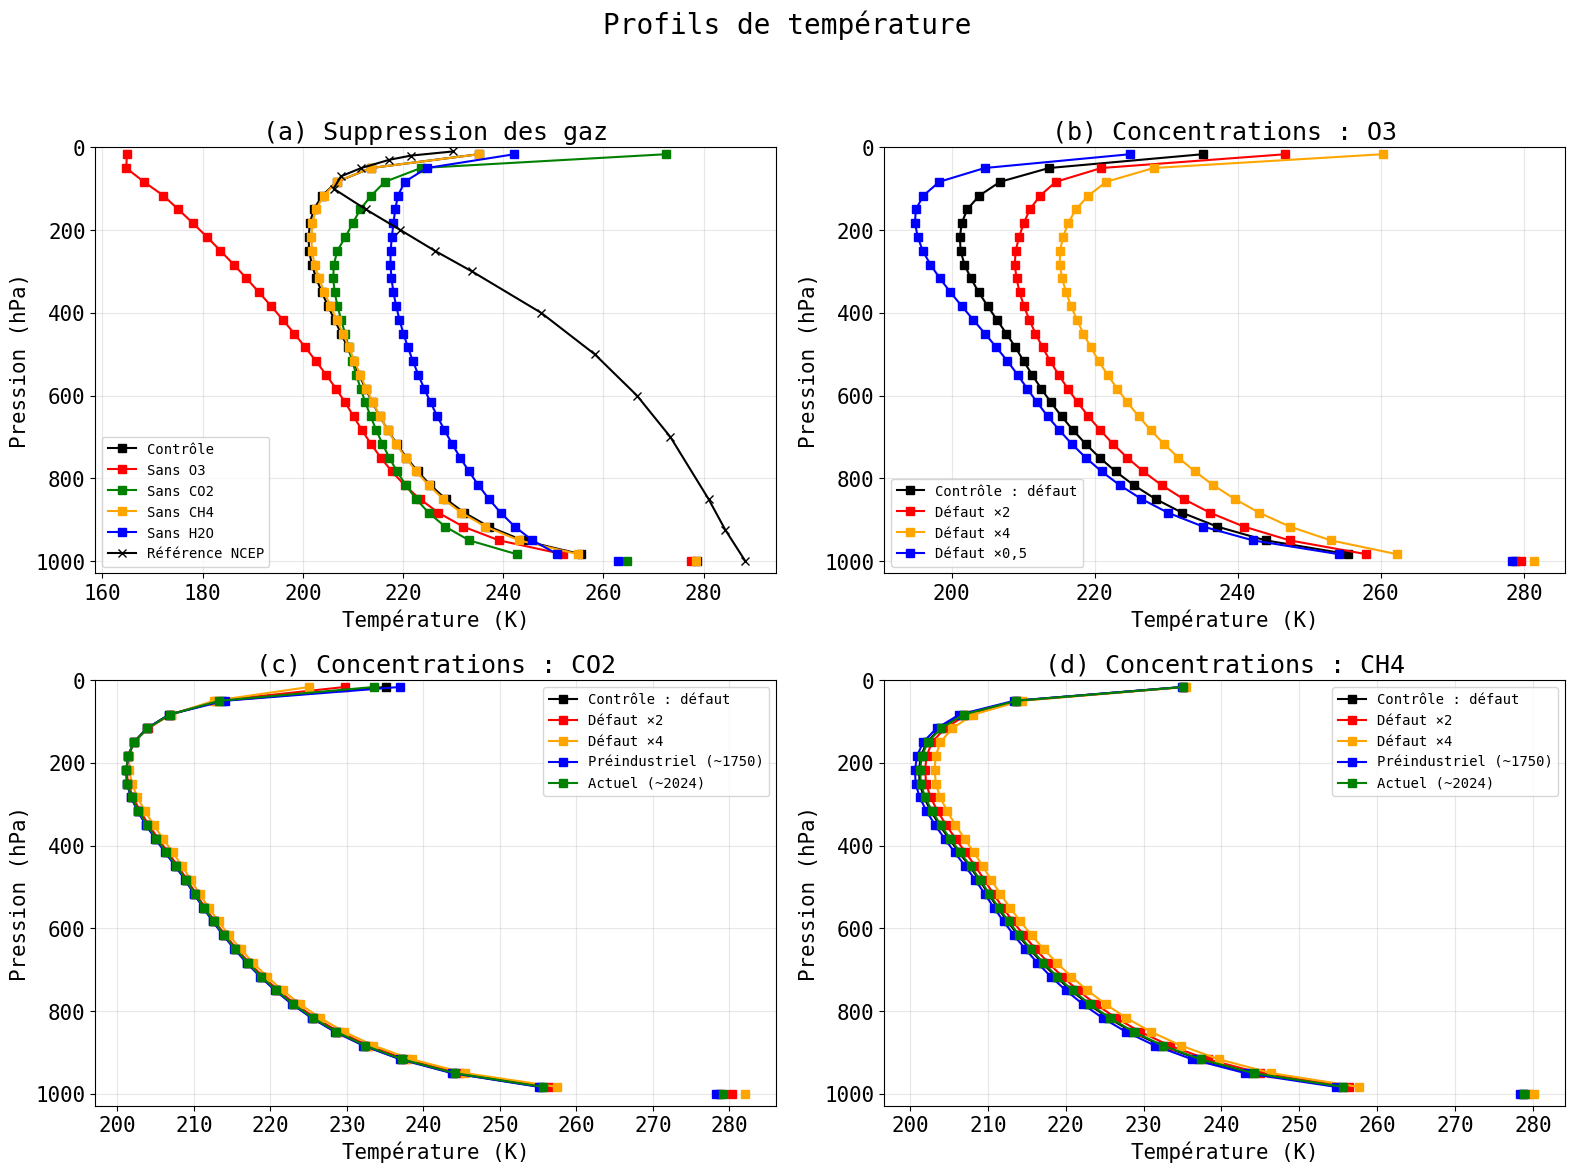

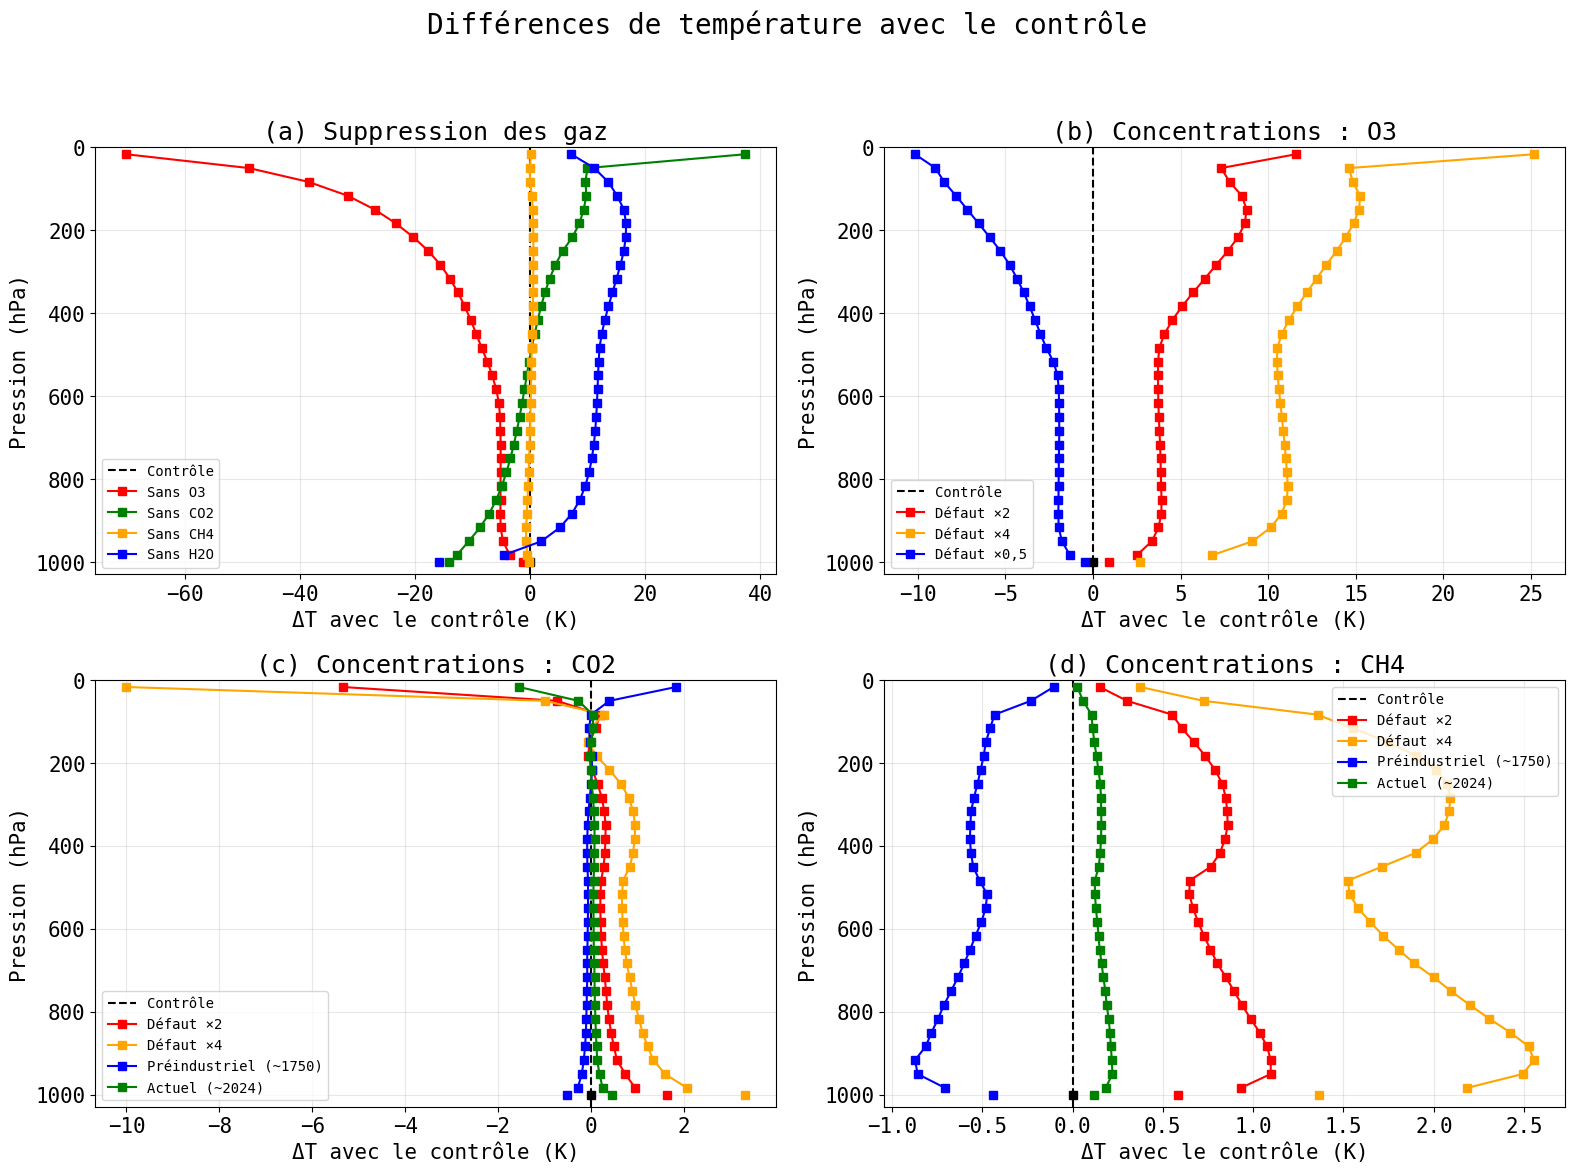

In [22]:
#!/usr/bin/env python
# coding: utf-8

import os
import copy as cp
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import climlab

# Pour fixer la taille de la police partout
font = {'family': 'monospace', 'size': 15}
matplotlib.rc('font', **font)

# Sensibilité aux concentrations de gaz
print('\n', '\n', '********************************************')
print('Sensitivity to the concentration of gases in the atmosphere')
print('********************************************')

gaz_etudies = ['O3', 'CO2', 'CH4']

# Contrôle des gaz
state_controle_gaz = climlab.column_state(num_lev=Nz)
h2o_controle_gaz = climlab.radiation.ManabeWaterVapor(
    name='WaterVapor', state=state_controle_gaz
)
rad_initial = climlab.radiation.RRTMG(
    name='Radiation',
    state=state_controle_gaz,
    specific_humidity=h2o_controle_gaz.q,
    albedo=alb
)
controle_gaz = climlab.couple(
    [rad_initial, h2o_controle_gaz], name='Radiative-Equilibrium Model'
)
controle_gaz.integrate_years(2)

Ts_controle = controle_gaz.Ts.item()
Tatm_controle = controle_gaz.Tatm
modeles_sans_gaz = {}

fig_temp, axes_temp = plt.subplots(2, 2, figsize=(16, 12))
fig_diff, axes_diff = plt.subplots(2, 2, figsize=(16, 12))

#  Comparaison des concentrations pour chaque gaz
for gi, gg in enumerate(gaz_etudies, start=1):
    valeur_defaut = rad_initial.absorber_vmr[gg]

    # Étiquette, concentration et couleur
    experiences = [
        ('Défaut ×2', 2 * valeur_defaut, 'red'),
        ('Défaut ×4', 4 * valeur_defaut, 'orange')
    ]

    if gg == 'CO2':
        experiences += [
            ('Préindustriel (~1750)', 278e-6, 'blue'),
            ('Actuel (~2024)', 422e-6, 'green')
        ]
    elif gg == 'CH4':
        experiences += [
            ('Préindustriel (~1750)', 730e-9, 'blue'),
            ('Actuel (~2024)', 1930e-9, 'green')
        ]
    elif gg == 'O3':
        experiences.append(('Défaut ×0,5', 0.5 * valeur_defaut, 'blue'))

    
    experiences.append(('Sans ' + gg, np.zeros_like(valeur_defaut), 'gray'))

    ax_temp = axes_temp.flat[gi]
    ax_diff = axes_diff.flat[gi]

    ax_temp.plot(
        controle_gaz.Tatm[::-1], controle_gaz.lev[::-1],
        marker='s', color='black', label='Contrôle : défaut'
    )
    ax_temp.plot(Ts_controle, 1000, marker='s', color='black')
    ax_diff.axvline(0, color='black', linestyle='--', label='Contrôle')
    ax_diff.plot(0, 1000, marker='s', color='black')

    print(f'\nRésultats pour {gg}')
    print(f"{'Expérience':<24} {'Ts (K)':>10} {'ΔTs (K)':>12}")
    print(f"{'Contrôle':<24} {Ts_controle:>10.2f} {0.0:>12.2f}")

    for etiquette, concentration, couleur in experiences:
        state = climlab.column_state(num_lev=Nz)
        h2o = climlab.radiation.ManabeWaterVapor(
            name='WaterVapor', state=state
        )
        rad = climlab.radiation.RRTMG(
            name='Radiation', state=state,
            specific_humidity=h2o.q, albedo=alb
        )
        modele = climlab.couple(
            [rad, h2o], name='Radiative-Equilibrium Model'
        )

        rad.absorber_vmr[gg] = concentration
        modele.integrate_years(2)  # Intègre le modèle sur deux ans

        if etiquette == 'Sans ' + gg:
            modeles_sans_gaz[gg] = modele
            continue

        Ts = modele.Ts.item()
        delta_Ts = Ts - Ts_controle
        delta_Tatm = modele.Tatm - Tatm_controle

        ax_temp.plot(
            modele.Tatm[::-1], modele.lev[::-1],
            marker='s', color=couleur, label=etiquette
        )
        ax_temp.plot(Ts, 1000, marker='s', color=couleur)

        ax_diff.plot(
            delta_Tatm[::-1], modele.lev[::-1],
            marker='s', color=couleur, label=etiquette
        )
        ax_diff.plot(delta_Ts, 1000, marker='s', color=couleur)

        print(f"{etiquette:<24} {Ts:>10.2f} {delta_Ts:>+12.2f}")

    titre = f'({"abcd"[gi]}) Concentrations : {gg}'
    ax_temp.set_title(titre)
    ax_diff.set_title(titre)


# Suppression séparée de chaque gaz
print('\n', '\n', '********************************************')
print('Sensibilité : suppression de chaque gaz')
print('********************************************')

colors = ['k', 'r', 'g', 'orange', 'blue']
ax_temp = axes_temp[0, 0]
ax_diff = axes_diff[0, 0]

ax_temp.plot(
    controle_gaz.Tatm[::-1], controle_gaz.lev[::-1],
    marker='s', color=colors[0], label='Contrôle'
)
ax_temp.plot(Ts_controle, 1000, marker='s', color=colors[0])
ax_diff.axvline(0, color=colors[0], linestyle='--', label='Contrôle')
ax_diff.plot(0, 1000, marker='s', color=colors[0])

print(f"{'Expérience':<24} {'Ts (K)':>10} {'ΔTs (K)':>12}")
print(f"{'Contrôle':<24} {Ts_controle:>10.2f} {0.0:>12.2f}")

for gi, gg in enumerate(['O3', 'CO2', 'CH4', 'H2O'], start=1):
    if gg == 'H2O':
        # Humidité spécifique nulle à tous les niveaux.
        state = climlab.column_state(num_lev=Nz)
        rad = climlab.radiation.RRTMG(
            name='Radiation', state=state,
            specific_humidity=np.zeros_like(state.Tatm), albedo=alb
        )
        modele_sans_gaz = climlab.couple(
            [rad], name='Radiative-Equilibrium Model'
        )
        modele_sans_gaz.integrate_years(2)
    else:
        modele_sans_gaz = modeles_sans_gaz[gg]

    etiquette = 'Sans ' + gg
    couleur = colors[gi]
    Ts = modele_sans_gaz.Ts.item()
    delta_Ts = Ts - Ts_controle
    delta_Tatm = modele_sans_gaz.Tatm - Tatm_controle

    ax_temp.plot(
        modele_sans_gaz.Tatm[::-1], modele_sans_gaz.lev[::-1],
        marker='s', color=couleur, label=etiquette
    )
    ax_temp.plot(Ts, 1000, marker='s', color=couleur)

    ax_diff.plot(
        delta_Tatm[::-1], modele_sans_gaz.lev[::-1],
        marker='s', color=couleur, label=etiquette
    )
    ax_diff.plot(delta_Ts, 1000, marker='s', color=couleur)

    print(f"{etiquette:<24} {Ts:>10.2f} {delta_Ts:>+12.2f}")

ax_temp.plot(
    ncep_T, ncep_lev, marker='x', color='k', label='Référence NCEP'
)
ax_temp.set_title('(a) Suppression des gaz')
ax_diff.set_title('(a) Suppression des gaz')

# Format commun aux deux figures à quatre panneaux
for ax_temp, ax_diff in zip(axes_temp.flat, axes_diff.flat):
    ax_temp.set_xlabel('Température (K)')
    ax_diff.set_xlabel('ΔT avec le contrôle (K)')

    for ax in (ax_temp, ax_diff):
        ax.set_ylabel('Pression (hPa)')
        ax.set_ylim(1030, 0)
        ax.legend(fontsize=10)
        ax.grid(alpha=0.3)

fig_temp.suptitle('Profils de température', fontsize=20)
fig_temp.tight_layout(rect=[0, 0, 1, 0.95])
fig_name = 'sensibilite_temperatures_4_panneaux.png'
fig_temp.savefig(fig_name, bbox_inches='tight')
print('output figure:', fig_name)

fig_diff.suptitle('Différences de température avec le contrôle', fontsize=20)
fig_diff.tight_layout(rect=[0, 0, 1, 0.95])
fig_name = 'sensibilite_differences_4_panneaux.png'
fig_diff.savefig(fig_name, bbox_inches='tight')
print('output figure:', fig_name)

plt.show()
plt.close(fig_diff)
plt.close(fig_temp)


 
 ********************************************
Sensitivity to albedo
********************************************

Référence : albédo = 0.25 | Ts = 278.76 K
Écart recherché pour compenser approximativement +1.63 K : -1.63 K

Integrating for 730 steps, 730.4844 days, or 2 years.
Total elapsed time is 1.9986737567564754 years.
Albédo = 0.250 | Ts = 278.76 K | Écart au contrôle = +0.00 K
Integrating for 730 steps, 730.4844 days, or 2 years.
Total elapsed time is 1.9986737567564754 years.
Albédo = 0.260 | Ts = 277.68 K | Écart au contrôle = -1.08 K
Integrating for 730 steps, 730.4844 days, or 2 years.
Total elapsed time is 1.9986737567564754 years.
Albédo = 0.270 | Ts = 276.59 K | Écart au contrôle = -2.17 K
Integrating for 730 steps, 730.4844 days, or 2 years.
Total elapsed time is 1.9986737567564754 years.
Albédo = 0.280 | Ts = 275.49 K | Écart au contrôle = -3.28 K
Integrating for 730 steps, 730.4844 days, or 2 years.
Total elapsed time is 1.9986737567564754 years.
Albédo = 0.290 | Ts

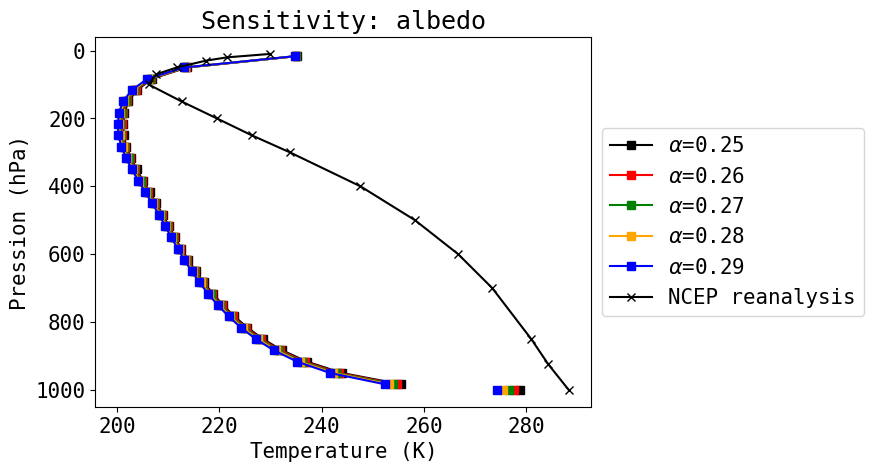


 
 ********************************************
Sensitivity to albedo
********************************************
Integrating for 730 steps, 730.4844 days, or 2 years.
Total elapsed time is 1.9986737567564754 years.
Integrating for 730 steps, 730.4844 days, or 2 years.
Total elapsed time is 1.9986737567564754 years.
Integrating for 730 steps, 730.4844 days, or 2 years.
Total elapsed time is 1.9986737567564754 years.
Integrating for 730 steps, 730.4844 days, or 2 years.
Total elapsed time is 1.9986737567564754 years.
output figure:  albedo_OG.png


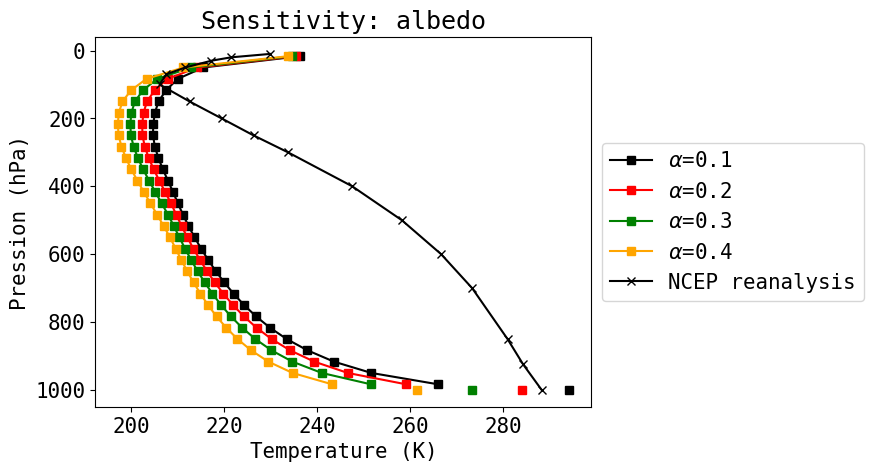

In [25]:

print('\n','\n','********************************************')
print('Sensitivity to albedo')
print('********************************************')

# albédo proche 
albedos=[.25,.26,.27,.28,.29]
colors=['k','r','g','orange','blue']

rcms={}
for alb in albedos:
    state = climlab.column_state(num_lev=30)
    h2o = climlab.radiation.ManabeWaterVapor(name='WaterVapor', state=state)
    rad = climlab.radiation.RRTMG(name='Radiation', state=state, specific_humidity=h2o.q, albedo=alb)
    rcm = climlab.couple([rad,h2o], name='Radiative-Equilibrium Model')
    rcms['rcm'+str(alb)]=rcm

print(f'\nRéférence : albédo = 0.25 | Ts = {Ts_controle:.2f} K')
print('Écart recherché pour compenser approximativement +1.63 K : -1.63 K\n')

for ai,alb in enumerate(albedos):
    rcms['rcm'+str(alb)].integrate_years(2)

    # température de surface et écart au contrôle
    Ts_albedo=np.asarray(rcms['rcm'+str(alb)].Ts).item()
    ecart=Ts_albedo-Ts_controle

    print(f'Albédo = {alb:.3f} | Ts = {Ts_albedo:.2f} K | Écart au contrôle = {ecart:+.2f} K')

    plt.plot(rcms['rcm'+str(alb)].Tatm[::-1], rcms['rcm'+str(alb)].lev[::-1], marker='s', label=r'$\alpha$='+str(np.round(alb,3)),color=colors[ai])
    plt.plot(rcms['rcm'+str(alb)].Ts, 1000, marker='s',color=colors[ai])

plt.plot(ncep_T, ncep_lev, marker='x',color='k',label='NCEP reanalysis')
plt.gca().invert_yaxis()
plt.title('Sensitivity: albedo')
plt.ylabel('Pression (hPa)')
plt.xlabel('Temperature (K)')
plt.gca().legend(loc='center left', bbox_to_anchor=(1, 0.5))

fig_name='albedo_comparaison.png'
print('output figure: ', fig_name)
plt.savefig(fig_name,bbox_inches='tight')
plt.show()
plt.close()

print('\n','\n','********************************************')
print('Sensitivity to albedo')
print('********************************************')
albedos=np.arange(.1,.4,.1)
rcms={}
for alb in albedos:
    state = climlab.column_state(num_lev=30)
    h2o = climlab.radiation.ManabeWaterVapor(name='WaterVapor', state=state)
    rad = climlab.radiation.RRTMG(name='Radiation', state=state, specific_humidity=h2o.q, albedo=alb)
    rcm = climlab.couple([rad,h2o], name='Radiative-Equilibrium Model')
    rcms['rcm'+str(alb)]=rcm

for ai,alb in enumerate(albedos):
    rcms['rcm'+str(alb)].integrate_years(2)
    plt.plot(rcms['rcm'+str(alb)].Tatm[::-1], rcm.lev[::-1], marker='s', label=r'$\alpha$='+str(np.round(alb,1)),color=colors[ai])
    plt.plot(rcms['rcm'+str(alb)].Ts, 1000, marker='s',color=colors[ai])
plt.plot(ncep_T, ncep_lev, marker='x',color='k',label='NCEP reanalysis')
plt.gca().invert_yaxis()
plt.title('Sensitivity: albedo')
plt.ylabel('Pression (hPa)')
plt.xlabel('Temperature (K)')
plt.gca().legend(loc='center left', bbox_to_anchor=(1, 0.5))
fig_name='albedo_OG.png'
print('output figure: ', fig_name)
plt.savefig(fig_name,bbox_inches='tight')
plt.show()
plt.close()


In [26]:

print('\n','\n','********************************************')
print('Sensitivity to convection')
print('********************************************')
alb=0.25
# Chaque modele doit avoir son propre etat (state) et ses propres processus :
# s'ils etaient partages, l'integration d'un modele modifierait l'etat des autres.
rcms={}
for ai,lapse in enumerate([None,6.5,9.8,'MALR']): # gradient vertical de température en degC par km (None = sans convection)
    state = climlab.column_state(num_lev=30)
    h2o = climlab.radiation.ManabeWaterVapor(name='WaterVapor', state=state)
    rad = climlab.radiation.RRTMG(name='Radiation', state=state, specific_humidity=h2o.q, albedo=alb)
    if lapse is None:
        rcms['rcm'+str(ai)] = climlab.couple([rad,h2o], name='Radiative-Equilibrium Model')
    else:
        conv = climlab.convection.ConvectiveAdjustment(name='Convection', state=state, adj_lapse_rate=lapse)
        rcms['rcm'+str(ai)] = climlab.couple([rad,conv,h2o], name='Radiative-Convective Model')

mod_name=['no-conv','conv-6.5','conv-9.8','conv-MALR']
for ai in range(4):
    rcms['rcm'+str(ai)].integrate_years(2)
    plt.plot(rcms['rcm'+str(ai)].Tatm[::-1], rcm.lev[::-1], marker='s', label=mod_name[ai],color=colors[ai])
    plt.plot(rcms['rcm'+str(ai)].Ts, 1000, marker='s',color=colors[ai])
plt.plot(ncep_T, ncep_lev, marker='x',color='k',label='NCEP reanalysis')
plt.gca().invert_yaxis()
plt.title('Sensitivity: convection')
plt.ylabel('Pression (hPa)')
plt.xlabel('Temperature (K)')
plt.gca().legend(loc='center left', bbox_to_anchor=(1, 0.5))
fig_name='convection_comparaison.png'
print('output figure: ', fig_name)
plt.savefig(fig_name,bbox_inches='tight')
plt.close()


 
 ********************************************
Sensitivity to convection
********************************************
Integrating for 730 steps, 730.4844 days, or 2 years.
Total elapsed time is 1.9986737567564754 years.
Integrating for 730 steps, 730.4844 days, or 2 years.
Total elapsed time is 1.9986737567564754 years.
Integrating for 730 steps, 730.4844 days, or 2 years.
Total elapsed time is 1.9986737567564754 years.
Integrating for 730 steps, 730.4844 days, or 2 years.
Total elapsed time is 1.9986737567564754 years.
output figure:  convection_comparaison.png


In [27]:
alb = 0.25
CO2_ppm = 800  #concentration en ppm

rcms2 = {}

for ai, lapse in enumerate([None, 6.5, 9.8, 'MALR']):
    state = climlab.column_state(num_lev=30)
    h2o = climlab.radiation.ManabeWaterVapor(name='WaterVapor',state=state)
    rad = climlab.radiation.RRTMG(name='Radiation',state=state,specific_humidity=h2o.q,albedo=alb)
    # Concentration de CO2 changé
    rad.absorber_vmr['CO2'] = CO2_ppm * 1e-6
    if lapse is None:
        rcms2['rcm' + str(ai)] = climlab.couple([rad, h2o],name='Radiative-Equilibrium Model')
    else:
        conv = climlab.convection.ConvectiveAdjustment(name='Convection',state=state,adj_lapse_rate=lapse)
        rcms2['rcm' + str(ai)] = climlab.couple([rad, conv, h2o],name='Radiative-Convective Model')
mod_name=['no-conv','conv-6.5','conv-9.8','conv-MALR']
for ai in range(4):
    rcms2['rcm'+str(ai)].integrate_years(2)
    plt.plot(rcms2['rcm'+str(ai)].Tatm[::-1], rcm.lev[::-1], marker='s', label=mod_name[ai],color=colors[ai])
    plt.plot(rcms2['rcm'+str(ai)].Ts, 1000, marker='s',color=colors[ai])
plt.plot(ncep_T, ncep_lev, marker='x',color='k',label='NCEP reanalysis')
plt.gca().invert_yaxis()
plt.title('Sensitivity: convection')
plt.ylabel('Pression (hPa)')
plt.xlabel('Temperature (K)')
plt.gca().legend(loc='center left', bbox_to_anchor=(1, 0.5))
fig_name='convection_comparaison_CO2.png'
print('output figure: ', fig_name)
plt.savefig(fig_name,bbox_inches='tight')
plt.close()

Integrating for 730 steps, 730.4844 days, or 2 years.
Total elapsed time is 1.9986737567564754 years.
Integrating for 730 steps, 730.4844 days, or 2 years.
Total elapsed time is 1.9986737567564754 years.
Integrating for 730 steps, 730.4844 days, or 2 years.
Total elapsed time is 1.9986737567564754 years.
Integrating for 730 steps, 730.4844 days, or 2 years.
Total elapsed time is 1.9986737567564754 years.
output figure:  convection_comparaison_CO2.png



 
 ********************************************
Sensitivity to convection
********************************************
Integrating for 730 steps, 730.4844 days, or 2 years.
Total elapsed time is 1.9986737567564754 years.
output figure:  convection_comparaison.png
Integrating for 730 steps, 730.4844 days, or 2 years.
Total elapsed time is 1.9986737567564754 years.
output figure:  convection_comparaison_CO2.png


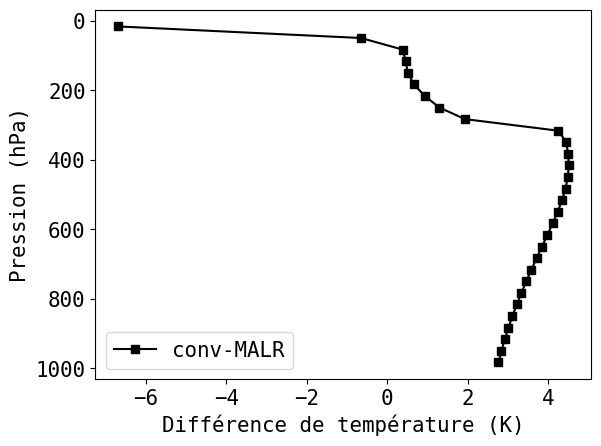

In [28]:

print('\n','\n','********************************************')
print('Sensitivity to convection')
print('********************************************')
alb=0.25
# Chaque modele doit avoir son propre etat (state) et ses propres processus :
# s'ils etaient partages, l'integration d'un modele modifierait l'etat des autres.
rcms={}
for ai, lapse in enumerate(['MALR']): # gradient vertical de température en degC par km (None = sans convection)
    state = climlab.column_state(num_lev=30)
    h2o = climlab.radiation.ManabeWaterVapor(name='WaterVapor', state=state)
    rad = climlab.radiation.RRTMG(name='Radiation', state=state, specific_humidity=h2o.q, albedo=alb)
    if lapse is None:
        rcms['rcm'+str(ai)] = climlab.couple([rad,h2o], name='Radiative-Equilibrium Model')
    else:
        conv = climlab.convection.ConvectiveAdjustment(name='Convection', state=state, adj_lapse_rate=lapse)
        rcms['rcm'+str(ai)] = climlab.couple([rad,conv,h2o], name='Radiative-Convective Model')

mod_name=['conv-MALR']
for ai in range(len(mod_name)):
    rcms['rcm'+str(ai)].integrate_years(2)
    plt.plot(rcms['rcm'+str(ai)].Tatm[::-1], rcm.lev[::-1], marker='s', label=mod_name[ai],color=colors[ai])
    plt.plot(rcms['rcm'+str(ai)].Ts, 1000, marker='s',color=colors[ai])
plt.plot(ncep_T, ncep_lev, marker='x',color='k',label='NCEP reanalysis')
plt.gca().invert_yaxis()
plt.title('Sensitivity: convection')
plt.ylabel('Pression (hPa)')
plt.xlabel('Temperature (K)')
plt.gca().legend(loc='center left', bbox_to_anchor=(1, 0.5))
fig_name='convection_comparaison.png'
print('output figure: ', fig_name)
plt.savefig(fig_name,bbox_inches='tight')
plt.close()


alb = 0.25
CO2_ppm =  844  #concentration en ppm

rcms2 = {}

for ai, lapse in enumerate(['MALR']):
    state = climlab.column_state(num_lev=30)
    h2o = climlab.radiation.ManabeWaterVapor(name='WaterVapor',state=state)
    rad = climlab.radiation.RRTMG(name='Radiation',state=state,specific_humidity=h2o.q,albedo=alb)
    # Concentration de CO2 changé
    rad.absorber_vmr['CO2'] = CO2_ppm * 1e-6
    if lapse is None:
        rcms2['rcm' + str(ai)] = climlab.couple([rad, h2o],name='Radiative-Equilibrium Model')
    else:
        conv = climlab.convection.ConvectiveAdjustment(name='Convection',state=state,adj_lapse_rate=lapse)
        rcms2['rcm' + str(ai)] = climlab.couple([rad, conv, h2o],name='Radiative-Convective Model')
mod_name=['conv-MALR']
for ai in range(len(mod_name)):
    rcms2['rcm'+str(ai)].integrate_years(2)
    plt.plot(rcms2['rcm'+str(ai)].Tatm[::-1], rcm.lev[::-1], marker='s', label=mod_name[ai],color=colors[ai])
    plt.plot(rcms2['rcm'+str(ai)].Ts, 1000, marker='s',color=colors[ai])
plt.plot(ncep_T, ncep_lev, marker='x',color='k',label='NCEP reanalysis')
plt.gca().invert_yaxis()
plt.title('Sensitivity: convection avec CO2')
plt.ylabel('Pression (hPa)')
plt.xlabel('Temperature (K)')
plt.gca().legend(loc='center left', bbox_to_anchor=(1, 0.5))
fig_name='convection_comparaison_CO2.png'
print('output figure: ', fig_name)
plt.savefig(fig_name,bbox_inches='tight')
plt.close()


rcm_mix = rcms2['rcm'+str(ai)].Tatm[::-1] - rcms['rcm'+str(ai)].Tatm[::-1]

plt.plot(rcm_mix, rcms['rcm'+str(ai)].lev[::-1],marker='s', label=mod_name[ai], color=colors[ai])
plt.gca().invert_yaxis()
plt.xlabel('Différence de température (K)')
plt.ylabel('Pression (hPa)')
plt.legend()
plt.savefig("sensibilite_climatique_convection")
plt.show()

In [29]:
modele = rcms['rcm0']

print('\nFlux du modèle avec convection MALR')
print(f'ASR : {modele.ASR.item():.2f} W/m²')
print(f'OLR : {modele.OLR.item():.2f} W/m²')
print(f'LW descendant à la surface : {modele.LW_flux_down[-1].item():.2f} W/m²')
print(f'LW montant à la surface : {modele.LW_flux_up[-1].item():.2f} W/m²')


Flux du modèle avec convection MALR
ASR : 251.90 W/m²
OLR : 251.90 W/m²
LW descendant à la surface : 265.48 W/m²
LW montant à la surface : 360.72 W/m²



Résultats pour un réchauffement de +2.00 °C

Couverture englacée initiale : 6.03 %
Couverture englacée finale   : 3.87 %
Diminution de couverture    : 2.16 points de pourcentage

Albédo moyen initial : 0.3150
Albédo moyen final   : 0.3096
Changement d’albédo  : -0.0055


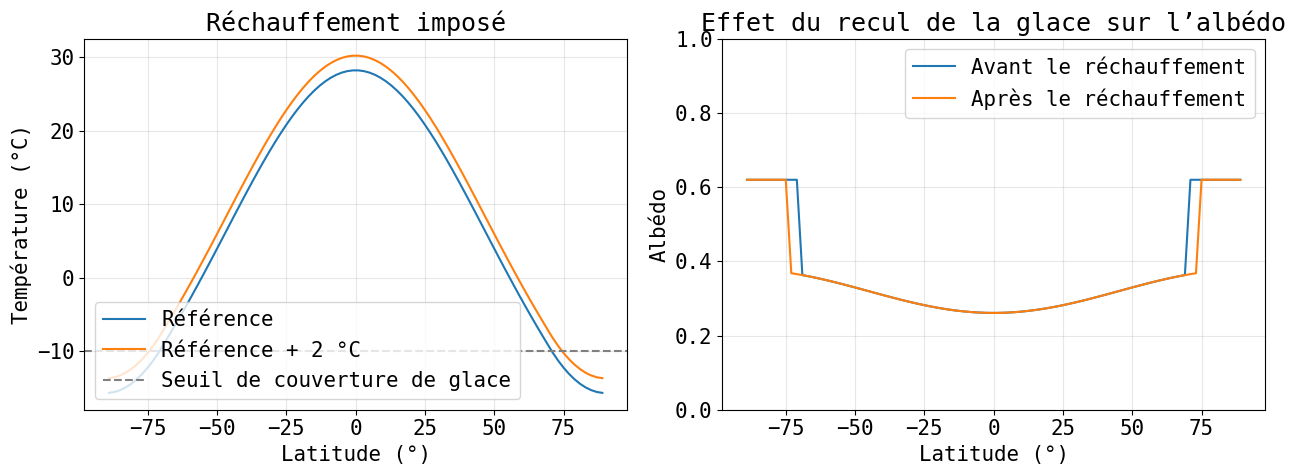

In [33]:
import numpy as np
import matplotlib.pyplot as plt
import climlab
from climlab import constants


delta_T = 2.0 
# Seuil empirique de couverture de glace du modèle annuel.
Tf = -10.0

# ==========================================================
# MODÈLE AVEC RÉTROACTION GLACE–ALBÉDO
# ==========================================================

modele_glace = climlab.EBM()

# référence
modele_glace.integrate_years(30, verbose=False)
modele_glace.compute_diagnostics(num_iter=3)

latitudes = modele_glace.lat.copy()
T_initiale = modele_glace.Ts.copy()
albedo_initial = modele_glace.albedo.copy()

glace_initiale = np.asarray(modele_glace.ice_area).item()
albedo_moyen_initial = np.asarray( climlab.global_mean(modele_glace.albedo)).item()

# ==========================================================
# APPLICATION DELTA T
# ==========================================================

# Hypothèse : réchauffement uniforme à toutes les latitudes
modele_glace.Ts[:] = T_initiale + delta_T

# Recalcul de la couverture de glace et de l'albédo.
modele_glace.compute_diagnostics(num_iter=3)

T_finale = modele_glace.Ts.copy()
albedo_final = modele_glace.albedo.copy()

glace_finale = np.asarray(modele_glace.ice_area).item()
albedo_moyen_final = np.asarray(climlab.global_mean(modele_glace.albedo)).item()

# ==========================================================
# RÉSULTATS
# ==========================================================

print('\nRésultats pour un réchauffement de '
      f'{delta_T:+.2f} °C')

print(f'\nCouverture englacée initiale : {100 * glace_initiale:.2f} %')
print(f'Couverture englacée finale   : {100 * glace_finale:.2f} %')

print('Diminution de couverture    : '
      f'{100 * (glace_initiale - glace_finale):.2f} '
      'points de pourcentage')

print(f'\nAlbédo moyen initial : {albedo_moyen_initial:.4f}')
print(f'Albédo moyen final   : {albedo_moyen_final:.4f}')
print('Changement d’albédo  : '
      f'{albedo_moyen_final - albedo_moyen_initial:+.4f}')

# ==========================================================
# GRAPHIQUES
# ==========================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Température
axes[0].plot(
    latitudes, T_initiale.squeeze(),
    label='Référence'
)
axes[0].plot(
    latitudes, T_finale.squeeze(),
    label=f'Référence + {delta_T:g} °C'
)
axes[0].axhline(
    Tf, color='gray', linestyle='--',
    label='Seuil de couverture de glace'
)
axes[0].set_xlabel('Latitude (°)')
axes[0].set_ylabel('Température (°C)')
axes[0].set_title('Réchauffement imposé')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Albédo
axes[1].plot(
    latitudes, albedo_initial.squeeze(),
    label='Avant le réchauffement'
)
axes[1].plot(
    latitudes, albedo_final.squeeze(),
    label='Après le réchauffement'
)
axes[1].set_xlabel('Latitude (°)')
axes[1].set_ylabel('Albédo')
axes[1].set_ylim(0, 1)
axes[1].set_title('Effet du recul de la glace sur l’albédo')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("Glace2K")
plt.show()


Résultats pour un réchauffement de +5.00 °C

Couverture englacée initiale : 6.03 %
Couverture englacée finale   : 0.55 %
Diminution de couverture    : 5.48 points de pourcentage

Albédo moyen initial : 0.3150
Albédo moyen final   : 0.3013
Changement d’albédo  : -0.0137


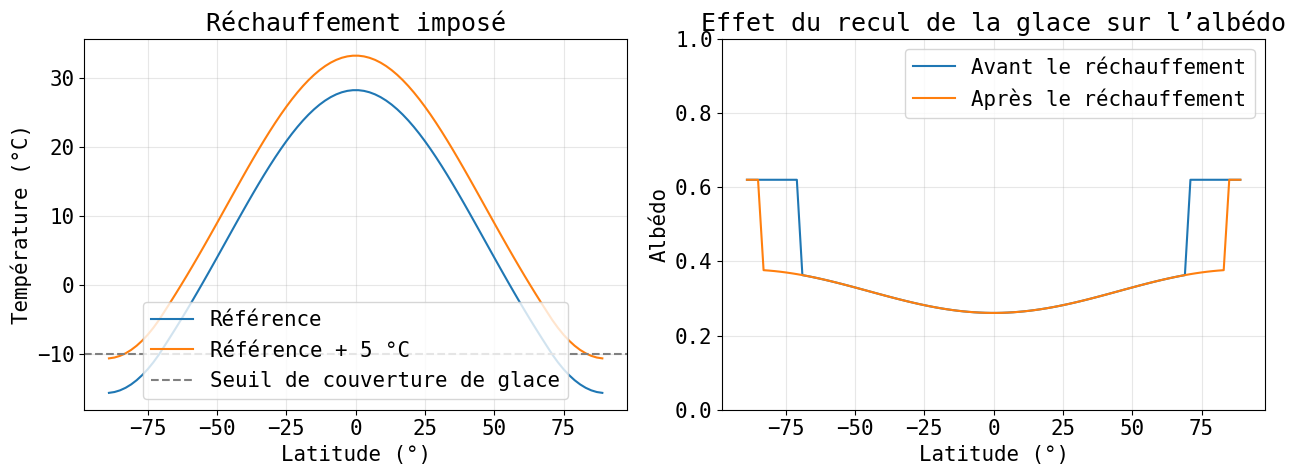

In [34]:
import numpy as np
import matplotlib.pyplot as plt
import climlab
from climlab import constants


delta_T = 5.0 
# Seuil empirique de couverture de glace du modèle annuel.
Tf = -10.0

# ==========================================================
# MODÈLE AVEC RÉTROACTION GLACE–ALBÉDO
# ==========================================================

modele_glace = climlab.EBM()

# référence
modele_glace.integrate_years(30, verbose=False)
modele_glace.compute_diagnostics(num_iter=3)

latitudes = modele_glace.lat.copy()
T_initiale = modele_glace.Ts.copy()
albedo_initial = modele_glace.albedo.copy()

glace_initiale = np.asarray(modele_glace.ice_area).item()
albedo_moyen_initial = np.asarray( climlab.global_mean(modele_glace.albedo)).item()

# ==========================================================
# APPLICATION DELTA T
# ==========================================================

# Hypothèse : réchauffement uniforme à toutes les latitudes
modele_glace.Ts[:] = T_initiale + delta_T

# Recalcul de la couverture de glace et de l'albédo.
modele_glace.compute_diagnostics(num_iter=3)

T_finale = modele_glace.Ts.copy()
albedo_final = modele_glace.albedo.copy()

glace_finale = np.asarray(modele_glace.ice_area).item()
albedo_moyen_final = np.asarray(climlab.global_mean(modele_glace.albedo)).item()

# ==========================================================
# RÉSULTATS
# ==========================================================

print('\nRésultats pour un réchauffement de '
      f'{delta_T:+.2f} °C')

print(f'\nCouverture englacée initiale : {100 * glace_initiale:.2f} %')
print(f'Couverture englacée finale   : {100 * glace_finale:.2f} %')

print('Diminution de couverture    : '
      f'{100 * (glace_initiale - glace_finale):.2f} '
      'points de pourcentage')

print(f'\nAlbédo moyen initial : {albedo_moyen_initial:.4f}')
print(f'Albédo moyen final   : {albedo_moyen_final:.4f}')
print('Changement d’albédo  : '
      f'{albedo_moyen_final - albedo_moyen_initial:+.4f}')

# ==========================================================
# GRAPHIQUES
# ==========================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Température
axes[0].plot(
    latitudes, T_initiale.squeeze(),
    label='Référence'
)
axes[0].plot(
    latitudes, T_finale.squeeze(),
    label=f'Référence + {delta_T:g} °C'
)
axes[0].axhline(
    Tf, color='gray', linestyle='--',
    label='Seuil de couverture de glace'
)
axes[0].set_xlabel('Latitude (°)')
axes[0].set_ylabel('Température (°C)')
axes[0].set_title('Réchauffement imposé')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Albédo
axes[1].plot(
    latitudes, albedo_initial.squeeze(),
    label='Avant le réchauffement'
)
axes[1].plot(
    latitudes, albedo_final.squeeze(),
    label='Après le réchauffement'
)
axes[1].set_xlabel('Latitude (°)')
axes[1].set_ylabel('Albédo')
axes[1].set_ylim(0, 1)
axes[1].set_title('Effet du recul de la glace sur l’albédo')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("Glace5K")
plt.show()